# Tutorial 8_B Tasks: Object Detection using Faster R-CNN Pre-Trained Models in PyTorch



## Step 1: Imports and the pre-trained models

In [1]:
import os, time, glob, zipfile, json, random
import xml.etree.ElementTree as ET
from concurrent.futures import ThreadPoolExecutor

import numpy as np, cv2, requests
import matplotlib.pyplot as plt, matplotlib.patches as patches
import torch
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights,
    fasterrcnn_mobilenet_v3_large_fpn, FasterRCNN_MobileNet_V3_Large_FPN_Weights,
    fasterrcnn_mobilenet_v3_large_320_fpn, FasterRCNN_MobileNet_V3_Large_320_FPN_Weights)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# Three COCO pre-trained Faster R-CNN models
MODEL_ZOO = {
    "ResNet-50 FPN (tutorial model)": (fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights.DEFAULT),
    "MobileNetV3-Large FPN":          (fasterrcnn_mobilenet_v3_large_fpn, FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT),
    "MobileNetV3-Large 320 FPN":      (fasterrcnn_mobilenet_v3_large_320_fpn, FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.DEFAULT),
}

# COCO class names. The index in this list is the class id the model outputs.
COCO_CLASSES = FasterRCNN_ResNet50_FPN_Weights.DEFAULT.meta["categories"]

models = {}
for name, (builder, weights) in MODEL_ZOO.items():
    models[name] = builder(weights=weights).to(device).eval()
    print(f"loaded {name}: {sum(p.numel() for p in models[name].parameters())/1e6:.1f}M parameters")

device: cuda
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 166MB/s]


loaded ResNet-50 FPN (tutorial model): 41.8M parameters
Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 157MB/s]


loaded MobileNetV3-Large FPN: 19.4M parameters
Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 162MB/s]


loaded MobileNetV3-Large 320 FPN: 19.4M parameters


## Step 2: Detection and display functions (tutorial Steps 3 and 4)

In [2]:
@torch.no_grad()
def detect_objects(image_path, model, threshold=0.5):
    image = cv2.imread(image_path)
    if image is None:
        raise FileNotFoundError(f"Could not load image at {image_path}. Please check the file path.")
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    tensor = torch.from_numpy(image_rgb).permute(2, 0, 1).float().div(255).to(device)
    out = model([tensor])[0]                      # the model resizes the image internally
    keep = out["scores"] >= threshold             # drop low-confidence detections
    return (image_rgb, out["boxes"][keep].cpu().numpy(),
            out["labels"][keep].cpu().numpy(), out["scores"][keep].cpu().numpy())


def display_image_with_detections(image, boxes, class_ids, scores, title="", ax=None):
    # boxes are in pixels: [x1, y1, x2, y2]
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(image)
    for box, c, s in zip(boxes, class_ids, scores):
        x1, y1, x2, y2 = box
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="lime", linewidth=2))
        ax.text(x1, max(y1 - 4, 10), f"{COCO_CLASSES[int(c)]}: {s:.2f}", color="black", fontsize=8,
                bbox=dict(facecolor="lime", pad=1, edgecolor="none"))
    ax.set_title(title); ax.axis("off")

## Task 1: Test it with your own image

- **Your own image:** set `UPLOAD_OWN_IMAGE = True`, run the cell, and choose a file in the upload box. (Or put the path of an image already in Colab in `IMAGE_PATH`.)
- **Default:** a sample COCO image is downloaded so the notebook runs end to end.

Saving WhatsApp Image 2026-05-02 at 8.08.58 PM.jpeg to WhatsApp Image 2026-05-02 at 8.08.58 PM (1).jpeg


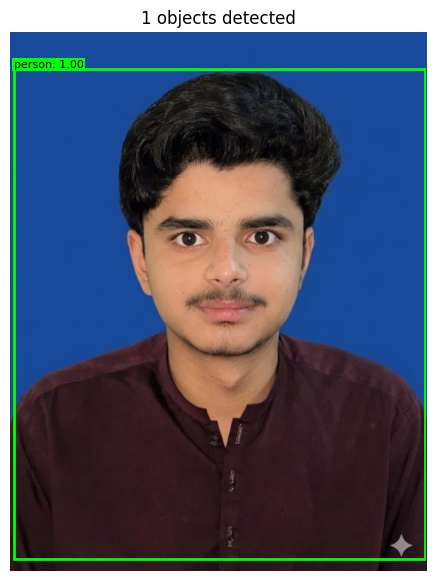

In [11]:
UPLOAD_OWN_IMAGE = True     # True = upload your own picture
IMAGE_PATH = "/content/WhatsApp Image 2026-05-02 at 8.08.58 PM.jpeg"

if UPLOAD_OWN_IMAGE:
    from google.colab import files
    IMAGE_PATH = list(files.upload())[0]
if IMAGE_PATH is None:
    IMAGE_PATH = "sample.jpg"
    # Added verify=False to bypass SSL certification check
    open(IMAGE_PATH, "wb").write(requests.get("https://images.cocodataset.org/val2017/000000039769.jpg", verify=False).content)

model = models["ResNet-50 FPN (tutorial model)"]
try:
    img, boxes, classes, scores = detect_objects(IMAGE_PATH, model, threshold=0.5)
    display_image_with_detections(img, boxes, classes, scores, title=f"{len(boxes)} objects detected")
except FileNotFoundError as e:
    print(e)

## Task 2: Two more models with different backbones



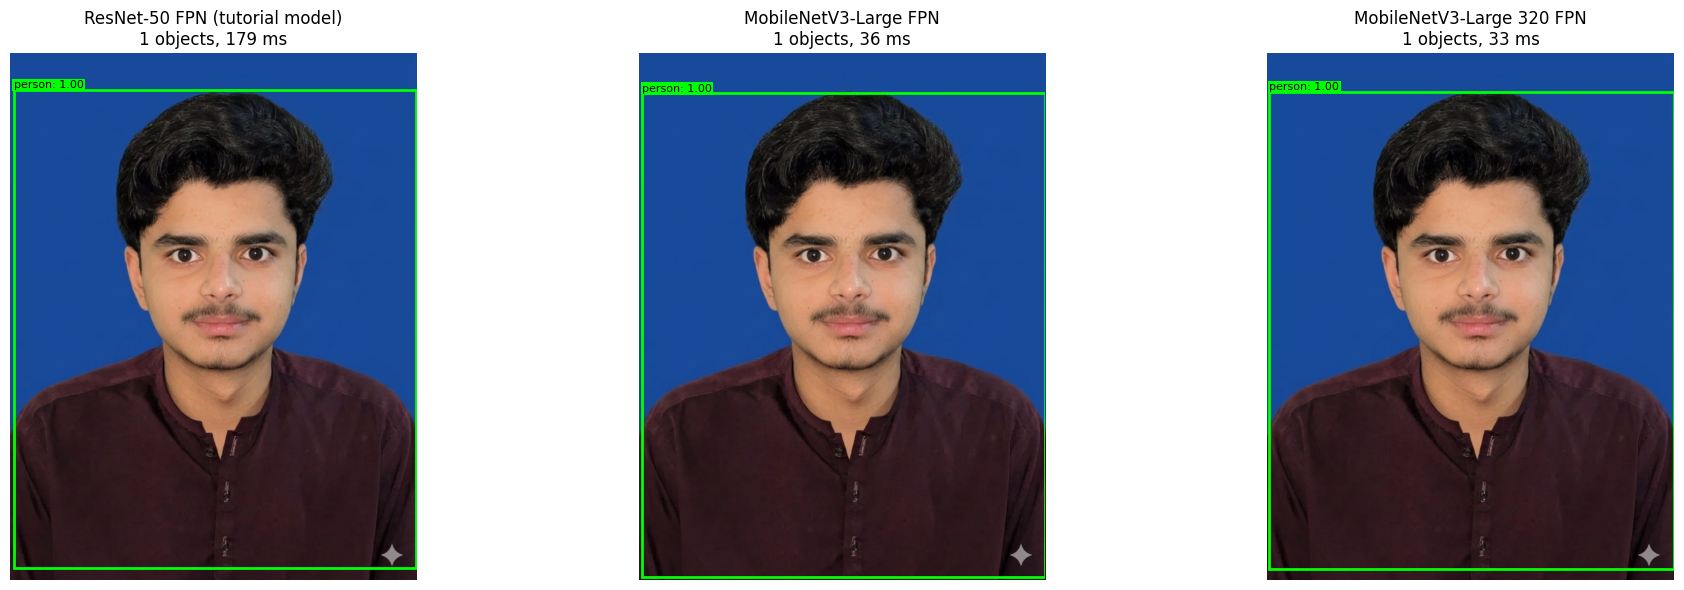

model                               params (M)   time (ms)  detections
ResNet-50 FPN (tutorial model)            41.8         179           1
MobileNetV3-Large FPN                     19.4          36           1
MobileNetV3-Large 320 FPN                 19.4          33           1


In [12]:
rows = []
fig, axs = plt.subplots(1, 3, figsize=(20, 6))
for ax, (name, m) in zip(axs, models.items()):
    detect_objects(IMAGE_PATH, m)                          # warm-up run
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    img, boxes, classes, scores = detect_objects(IMAGE_PATH, m, threshold=0.5)
    if device.type == "cuda": torch.cuda.synchronize()
    ms = (time.time() - t0) * 1000
    rows.append((name, sum(p.numel() for p in m.parameters()) / 1e6, ms, len(boxes)))
    display_image_with_detections(img, boxes, classes, scores, title=f"{name}\n{len(boxes)} objects, {ms:.0f} ms", ax=ax)
plt.tight_layout(); plt.show()

print(f"{'model':<34}{'params (M)':>12}{'time (ms)':>12}{'detections':>12}")
for r in rows: print(f"{r[0]:<34}{r[1]:>12.1f}{r[2]:>12.0f}{r[3]:>12}")

## Task 3: Evaluate on a bunch of data and find the mAP



In [20]:
EVAL_SOURCE =  "voc_zip"
NUM_EVAL_IMAGES = 100       # for "coco"
ZIP_PATH = "/content/150 data set.v1i.voc.zip"

def download(url, path):
    if not os.path.exists(path):
        # Added verify=False to bypass SSL certification check
        with requests.get(url, stream=True, verify=False) as r:
            r.raise_for_status()
            with open(path, "wb") as f:
                for chunk in r.iter_content(1 << 20): f.write(chunk)

samples = []     # list of (image_path, boxes [N,4] xyxy pixels, class_ids [N])

if EVAL_SOURCE == "coco":
    os.makedirs("coco_eval", exist_ok=True)
    download("https://images.cocodataset.org/annotations/annotations_trainval2017.zip", "coco_ann.zip")
    with zipfile.ZipFile("coco_ann.zip") as z:
        coco = json.load(z.open("annotations/instances_val2017.json"))
    per_image = {}
    for a in coco["annotations"]:
        x, y, w, h = a["bbox"]
        if a.get("iscrowd", 0) == 0 and w > 1 and h > 1:           # skip crowd regions
            per_image.setdefault(a["image_id"], []).append(([x, y, x + w, y + h], a["category_id"]))
    file_names = {im["id"]: im["file_name"] for im in coco["images"]}
    ids = sorted(per_image)[:NUM_EVAL_IMAGES]
    del coco
    def get_img(i):
        p = f"coco_eval/{file_names[i]}"
        download(f"https://images.cocodataset.org/val2017/{file_names[i]}", p); return p
    with ThreadPoolExecutor(8) as ex: paths = list(ex.map(get_img, ids))
    for p, i in zip(paths, ids):
        b, c = zip(*per_image[i])
        samples.append((p, np.array(b, np.float32), np.array(c, np.int64)))

else:   # your own VOC-labelled images
    ZIP_PATH = ZIP_PATH or (glob.glob("/content/*.zip") or [None])[0]
    if ZIP_PATH is None or not os.path.exists(ZIP_PATH):
        raise FileNotFoundError("No zip found. Upload your zip to /content and set ZIP_PATH.")
    with zipfile.ZipFile(ZIP_PATH) as z: z.extractall("/content/my_data")
    xmls = glob.glob("/content/my_data/**/*.xml", recursive=True)
    print("xml files found:", len(xmls))
    if not xmls: raise RuntimeError("No .xml files in the zip. Export labels as Pascal VOC (XML).")
    name_to_id = {n: i for i, n in enumerate(COCO_CLASSES) if n not in ("__background__", "N/A")}
    skipped = set()
    for xp in xmls:
        r = ET.parse(xp).getroot(); folder = os.path.dirname(xp)
        stem = os.path.splitext(os.path.basename(xp))[0]
        cand = [p for p in glob.glob(os.path.join(folder, stem + ".*")) if not p.endswith(".xml")]
        if not cand: print("image not found for", xp); continue
        b, c = [], []
        for o in r.findall("object"):
            n = o.findtext("name").strip().lower()
            if n not in name_to_id: skipped.add(n); continue
            bb = o.find("bndbox"); box = [float(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")]
            if box[2] > box[0] and box[3] > box[1]: b.append(box); c.append(name_to_id[n])
        if b: samples.append((cand[0], np.array(b, np.float32), np.array(c, np.int64)))
    if skipped: print("Labels not in COCO (ignored):", sorted(skipped))

print(f"Evaluation images: {len(samples)} | ground-truth boxes: {sum(len(s[1]) for s in samples)}")
if len(samples) == 0: raise RuntimeError("No usable evaluation images.")

xml files found: 234
Labels not in COCO (ignored): ['plate']
Evaluation images: 127 | ground-truth boxes: 200


### mAP function



In [21]:
def iou_one_to_many(b, g):
    x1, y1 = np.maximum(b[0], g[:, 0]), np.maximum(b[1], g[:, 1])
    x2, y2 = np.minimum(b[2], g[:, 2]), np.minimum(b[3], g[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    union = (b[2]-b[0])*(b[3]-b[1]) + (g[:, 2]-g[:, 0])*(g[:, 3]-g[:, 1]) - inter
    return inter / np.maximum(union, 1e-9)

def average_precision(rec, prec):
    mrec, mpre = np.r_[0, rec, 1], np.r_[0, prec, 0]
    for i in range(len(mpre) - 2, -1, -1): mpre[i] = max(mpre[i], mpre[i + 1])
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]))

def calc_map(preds, gts, iou_thr=0.5):
    aps = {}
    for c in sorted({int(l) for g in gts for l in g["labels"]}):
        dets, gtb, n_gt = [], {}, 0
        for i, (p, g) in enumerate(zip(preds, gts)):
            gtb[i] = g["boxes"][g["labels"] == c]; n_gt += len(gtb[i])
            m = p["labels"] == c
            dets += [(s, i, b) for b, s in zip(p["boxes"][m], p["scores"][m])]
        dets.sort(key=lambda d: -d[0])
        used = {i: np.zeros(len(b), bool) for i, b in gtb.items()}
        tp = np.zeros(len(dets))
        for k, (s, i, b) in enumerate(dets):
            if len(gtb[i]) == 0: continue
            ious = iou_one_to_many(b, gtb[i]); j = int(np.argmax(ious))
            if ious[j] >= iou_thr and not used[i][j]: tp[k] = 1; used[i][j] = True
        ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp)
        aps[c] = average_precision(ctp / n_gt, ctp / np.maximum(ctp + cfp, 1e-9))
    return float(np.mean(list(aps.values()))), aps

@torch.no_grad()
def run_on_samples(model, samples):
    preds, t0 = [], time.time()
    for path, _, _ in samples:
        rgb = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
        out = model([torch.from_numpy(rgb).permute(2, 0, 1).float().div(255).to(device)])[0]
        preds.append({k: v.cpu().numpy() for k, v in out.items()})
    if device.type == "cuda": torch.cuda.synchronize()
    return preds, (time.time() - t0) / len(samples) * 1000      # ms per image

gts = [{"boxes": b, "labels": l} for _, b, l in samples]

### Run all three models on the evaluation data

In [22]:
results, all_preds = {}, {}
for name, m in models.items():
    preds, ms = run_on_samples(m, samples)
    all_preds[name] = preds
    map50, per_class = calc_map(preds, gts, 0.5)
    map_coco = np.mean([calc_map(preds, gts, t)[0] for t in np.arange(0.5, 0.96, 0.05)])
    results[name] = {"mAP@0.5": map50, "mAP@[.5:.95]": float(map_coco), "ms": ms}
    print(f"{name:<34} mAP@0.5 = {map50:.3f} | mAP@[.5:.95] = {map_coco:.3f} | {ms:.0f} ms/image")

ResNet-50 FPN (tutorial model)     mAP@0.5 = 0.452 | mAP@[.5:.95] = 0.303 | 210 ms/image
MobileNetV3-Large FPN              mAP@0.5 = 0.414 | mAP@[.5:.95] = 0.279 | 103 ms/image
MobileNetV3-Large 320 FPN          mAP@0.5 = 0.401 | mAP@[.5:.95] = 0.251 | 103 ms/image


### Results

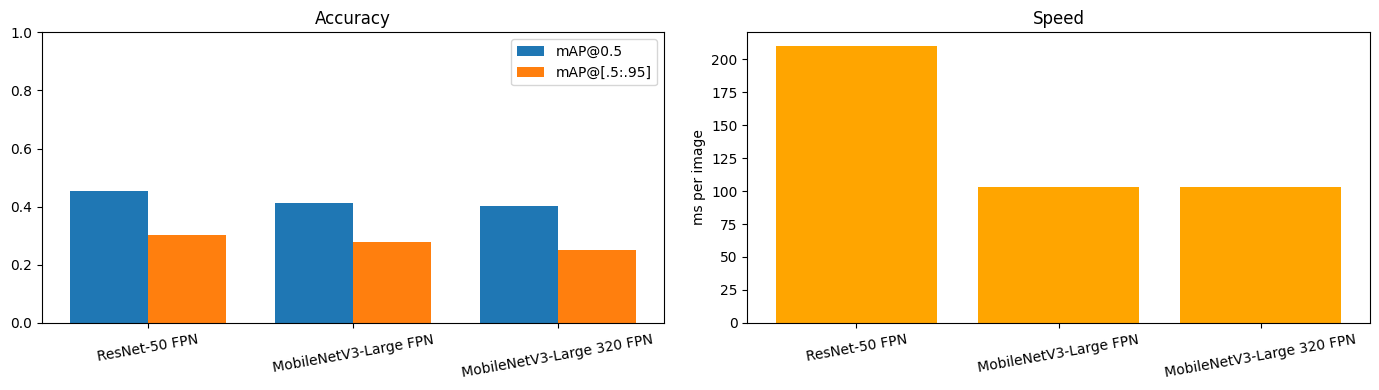

model                                mAP@0.5   mAP@[.5:.95]   ms/img
ResNet-50 FPN (tutorial model)         0.452          0.303      210
MobileNetV3-Large FPN                  0.414          0.279      103
MobileNetV3-Large 320 FPN              0.401          0.251      103


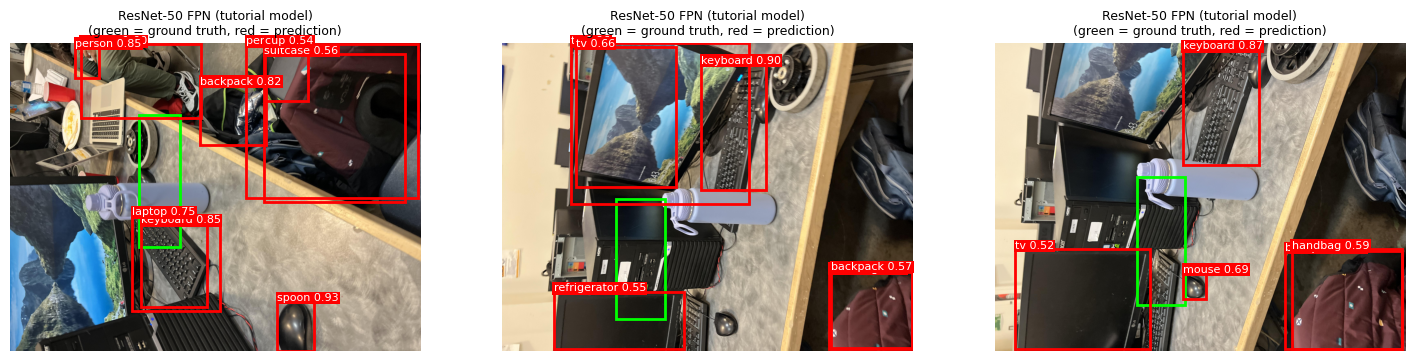

In [23]:
names = list(results)
short = [n.split(" (")[0] for n in names]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(names)); w = 0.38
ax[0].bar(x - w/2, [results[n]["mAP@0.5"] for n in names], w, label="mAP@0.5")
ax[0].bar(x + w/2, [results[n]["mAP@[.5:.95]"] for n in names], w, label="mAP@[.5:.95]")
ax[0].set_xticks(x); ax[0].set_xticklabels(short, rotation=10); ax[0].set_ylim(0, 1); ax[0].legend(); ax[0].set_title("Accuracy")
ax[1].bar(short, [results[n]["ms"] for n in names], color="orange")
ax[1].set_ylabel("ms per image"); ax[1].set_title("Speed"); plt.setp(ax[1].get_xticklabels(), rotation=10)
plt.tight_layout(); plt.show()

print(f"{'model':<34}{'mAP@0.5':>10}{'mAP@[.5:.95]':>15}{'ms/img':>9}")
for n in names:
    r = results[n]; print(f"{n:<34}{r['mAP@0.5']:>10.3f}{r['mAP@[.5:.95]']:>15.3f}{r['ms']:>9.0f}")

# ground truth (green) vs best model's predictions (red) on 3 random evaluation images
best = max(results, key=lambda n: results[n]["mAP@0.5"])
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
for ax, i in zip(axs, random.sample(range(len(samples)), min(3, len(samples)))):
    rgb = cv2.cvtColor(cv2.imread(samples[i][0]), cv2.COLOR_BGR2RGB); ax.imshow(rgb)
    for b in samples[i][1]:
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, edgecolor="lime", linewidth=2))
    p = all_preds[best][i]
    for b, l, s in zip(p["boxes"], p["labels"], p["scores"]):
        if s >= 0.5:
            ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, edgecolor="red", linewidth=2))
            ax.text(b[0], max(b[1]-4, 10), f"{COCO_CLASSES[int(l)]} {s:.2f}", color="white", fontsize=8, bbox=dict(facecolor="red", pad=1, edgecolor="none"))
    ax.set_title(f"{best}\n(green = ground truth, red = prediction)", fontsize=9); ax.axis("off")
plt.show()